# Graphite crust on a Mercury-like planet: fO$_2$ × carbon grid

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LogNorm, Normalize, SymLogNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import cmcrameri.cm as cmc

import utils.load_grid as lg
from proteus.utils.constants import condensate_density

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [5]:
pgrid_dir = "data/mercury_graphite_grid_v12"
outdir = "output/mercury_graphite_grid"
os.makedirs(outdir, exist_ok=True)

SATURATED = 0.999           # activity at and above which graphite counts as saturated
RHO_GRAPHITE = condensate_density["C"]   # [kg m-3]

# Mercury's present-day surface fO2 relative to IW (Sossi review)
MERCURY_DIW, MERCURY_DIW_ERR = -5.0, 0.4

# Low-reflectance material: initial crustal thickness, and its graphite equivalent [m]
LRM_CRUST_M = 4300.0
LRM_GRAPHITE_M = 120.0

In [6]:
cases = lg.get_cases(pgrid_dir, only_completed=True)
cfgs = lg.load_configs(cases)
helps, hvars = lg.load_helpfiles(cases)

dIW = np.array(lg.access_configs(cfgs, "outgas.fO2_shift_IW"), dtype=float)
Cb = np.array(lg.access_configs(cfgs, "planet.elements.C_budget"), dtype=float)
C_mode = lg.access_configs(cfgs, "planet.elements.C_mode")[0]
C_label = {"ppmw": "C [ppmw of mantle]", "C/H": "C/H mass ratio", "kg": "C [kg]"}.get(C_mode, "C budget")
print(f"{len(cases)} completed cases; carbon given as {C_mode}")

Configs:   0%|          | 0/50 [00:00<?, ?it/s]

outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false


Atmodeller initialized with double precision (float64)


Configs:   2%|▏         | 1/50 [00:01<00:54,  1.11s/it]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no eff

50 completed cases; carbon given as ppmw


In [7]:
rows, series = [], {}
for case, hf, x, y in zip(cases, helps, dIW, Cb):

    time = np.array(hf["Time"], dtype=float)
    act = np.array(hf["C_cd_activity"], dtype=float)
    mass = np.array(hf["C_cd_kg"], dtype=float)
    R = np.array(hf["R_int"], dtype=float)

    # thickness [m]
    thick =  mass / (4.0 * np.pi * R ** 2) / RHO_GRAPHITE

    sat = np.flatnonzero(act >= SATURATED)
    onset = time[sat[0]] if len(sat) else np.nan
    series[(x, y)] = (time, thick)
    rows.append(dict(case=os.path.basename(case), dIW=x, C=y,
                     time_end=time[-1] , T_end=hf["T_magma"].iloc[-1],
                     act_max=act.max(), thickness_m=thick[-1],
                     onset_yr=onset))

summary = pd.DataFrame(rows).sort_values(["dIW", "C"]).reset_index(drop=True)
summary.to_csv(os.path.join(outdir, "summary.csv"), index=False)
summary.round(3)

,case,dIW,C,time_end,T_end,act_max,thickness_m,onset_yr
0,case_000000,-7.0,31.623,14911.506,1650.898,0.000,0.000,NaN
1,case_000001,-7.0,31.623,14911.519,1650.889,0.154,0.000,NaN
2,case_000002,-7.0,100.000,16522.855,1661.997,0.000,0.000,NaN
3,case_000003,-7.0,100.000,16522.855,1661.997,0.488,0.000,NaN
4,case_000004,-7.0,316.228,19073.813,1683.590,0.000,0.000,NaN
5,case_000005,-7.0,316.228,18888.793,1684.873,1.000,55.014,11472.046
6,case_000006,-7.0,1000.000,21726.467,1704.939,0.000,0.000,NaN
7,case_000007,-7.0,1000.000,19782.703,1673.791,1.000,399.099,1349.079
8,case_000008,-7.0,3162.278,25503.433,1705.836,0.000,0.000,NaN
9,case_000009,-7.0,3162.278,19758.863,1678.746,1.000,1486.746,0.000


In [8]:
# Arrange onto the 2D parameter plane
xs = np.unique(summary["dIW"])
ys = np.unique(summary["C"])

def on_plane(col):
    Z = np.full((len(ys), len(xs)), np.nan)
    for _, r in summary.iterrows():
        Z[np.searchsorted(ys, r["C"]), np.searchsorted(xs, r["dIW"])] = r[col]
    return Z

def cell_edges(v, log=False):
    """Cell edges halfway between grid values (geometric midpoints on a log axis)."""
    v = np.log10(v) if log else np.asarray(v, dtype=float)
    if len(v) == 1:
        e = np.array([v[0] - 0.5, v[0] + 0.5])
    else:
        mid = 0.5 * (v[1:] + v[:-1])
        e = np.concatenate([[v[0] - (mid[0] - v[0])], mid, [v[-1] + (v[-1] - mid[-1])]])
    return 10 ** e if log else e

x_edges = cell_edges(xs)
y_edges = cell_edges(ys, log=True)

In [ ]:
def label(ax, x, y, txt):
    """Cell label with a thin outline in the opposite colour, above the fO2 band."""
    ax.text(x, y, txt, ha="center", va="center", fontsize=8, color='k', zorder=6,
            path_effects=[pe.withStroke(linewidth=2.0, foreground='w')])

def mesh(fig, ax, Z, cmap, norm, label_text, fmt, empty, empty_text):
    """Colour mesh of Z with per-cell labels; cells where `empty` is true are grey."""
    ax.pcolormesh(x_edges, y_edges, np.where(empty, 1.0, np.nan), cmap="Greys",
                  vmin=0, vmax=4, shading="flat")
    pm = ax.pcolormesh(x_edges, y_edges, np.ma.masked_where(empty, Z),
                       cmap=cmap, norm=norm, shading="flat")
    cb = fig.colorbar(pm, ax=ax, label=label_text) if not empty.all() else None
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            if np.isnan(Z[i, j]) and not empty[i, j]:
                continue
            if empty[i, j]:
                label(ax, x, y, empty_text)
            else:
                label(ax, x, y, fmt(i, j))
    return cb

## Endpoint crust and onset of saturation across the grid

[[3.154588955661384e-23 2.218090262994796e-23 2.313760875375858e-23
  2.162728955219310e-23 2.019735936715182e-23]
 [1.810837762709694e-22 1.252243831445588e-22 1.002166983000899e-22
  9.685843999342230e-23 8.775253671973524e-23]
 [5.501444719939348e+01 5.355534908277580e+00 7.063356381284897e-22
  5.091697545857767e-22 4.302513250081821e-22]
 [3.990993336329587e+02 3.463017107861318e+02 2.488457547086604e+02
  6.730931878194950e+01 2.796109017851190e-21]
 [1.486745864228787e+03 1.434473759241845e+03 1.337725525779918e+03
  1.156935128017244e+03 7.785730094641962e+02]]


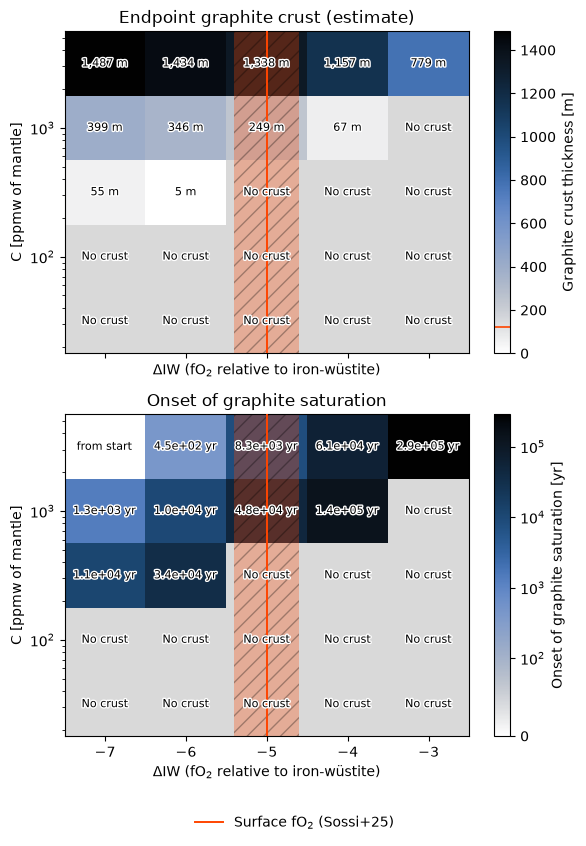

In [10]:
Z_t = on_plane("thickness_m")
Z_o = on_plane("onset_yr")

fig, axs = plt.subplots(2,1, figsize=(6,8), sharex=True, sharey=False)

none = (Z_t < 1e-3) 
pos = Z_t[(Z_t > 1e-3)]
print(Z_t)
norm_t = Normalize(vmin=0, vmax=max(pos.max(), 1.0))
cb = mesh(fig, axs[0], Z_t, cmc.oslo_r, norm_t,
          "Graphite crust thickness [m]", lambda i, j: f"{Z_t[i, j]:,.0f} m", none, "No crust")
if cb is not None:
    for v in (LRM_GRAPHITE_M, LRM_CRUST_M):
        if norm_t.vmin <= v <= norm_t.vmax:
            cb.ax.axhline(v, color="orangered", ls="solid", lw=1.2)
axs[0].set_title("Endpoint graphite crust (estimate)")

never = np.isnan(Z_o) #& ~missing
def fmt(i, j):
    v = Z_o[i, j]
    if v == 0:
        return "from start"
    return f"{v:.1e} yr"

vmax = np.nanmax(Z_o) if np.any(np.isfinite(Z_o)) else 1.0
mesh(fig, axs[1], Z_o, cmc.oslo_r, SymLogNorm(vmin=0, vmax=max(vmax, 1.0), linthresh=1e2),
     "Onset of graphite saturation [yr]", fmt, never, "No crust")
axs[1].set_title("Onset of graphite saturation")

for ax in axs:
    if ax is axs[0]:
        lbl = "Surface fO$_2$ (Sossi+25)"
    else:
        lbl = ""
    ax.axvspan(MERCURY_DIW - MERCURY_DIW_ERR, MERCURY_DIW + MERCURY_DIW_ERR,
                facecolor="orangered", edgecolor="k", hatch="//", lw=0, alpha=0.3, zorder=2)
    ax.axvline(MERCURY_DIW, color="orangered", ls="solid", lw=1.4, zorder=3, label=lbl)
    ax.set_yscale("log")
    # ax.set_xticks(xs)
    # ax.set_yticks(ys)
    ax.set_xlabel(r"$\Delta$IW (fO$_2$ relative to iron-wüstite)")
    ax.set_ylabel(C_label)

# handles = [Line2D([], [], color="k", ls="--", lw=1.4),
#             Patch(facecolor="none", edgecolor="k", hatch="//")]

fig.legend(loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(os.path.join(outdir, "graphite_grid_thickness_onset.pdf"), bbox_inches="tight")
plt.show()

## Graphite crust thickness against time

One panel per carbon budget, one line per fO$_2$. The dashed lines mark the LRM reference values: the observed initial crustal thickness (4.3 km) and its graphite equivalent (120 m). A line starts at the onset of saturation, since the thickness is zero before it.

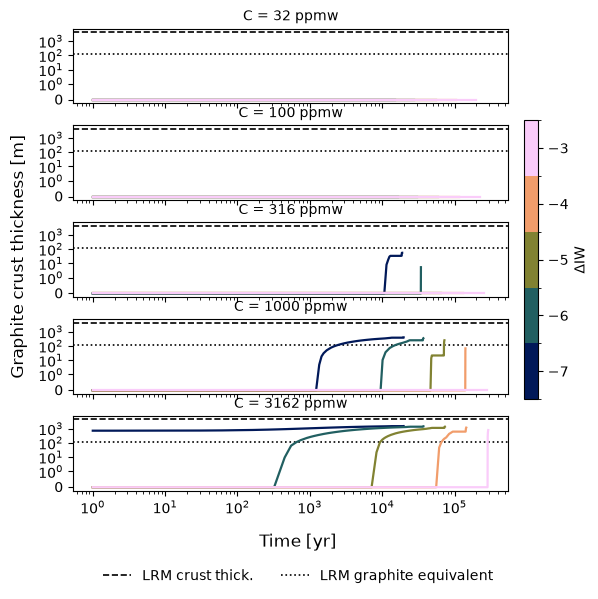

In [22]:
dIW_vals = np.unique(summary["dIW"])
C_vals = np.unique(summary["C"])
cmap_f = cmc.batlow
norm_f = BoundaryNorm(np.concatenate([dIW_vals - 0.5, [dIW_vals[-1] + 0.5]]), cmap_f.N)

nrow = len(C_vals)
fig, axs = plt.subplots(nrow, 1, figsize=(6.0, 1.2 * nrow), sharex=True, sharey=True, squeeze=False)
axs = axs[:, 0]
for ax, c in zip(axs, C_vals):
    for x in dIW_vals:
        if (x, c) not in series:
            continue
        time, thick = series[(x, c)]
        ok = (thick > 0) & (time > 0)
        if ok.any():
            ax.plot(time[ok], thick[ok], color=cmap_f(norm_f(x)), lw=1.6)
    for v, ls in ((LRM_CRUST_M, "--"), (LRM_GRAPHITE_M, ":")):
        ax.axhline(v, color="k", ls=ls, lw=1.2, zorder=1)
    ax.set_xscale("log")
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
fig.supxlabel("Time [yr]")
fig.supylabel("Graphite crust thickness [m]")

sm = plt.cm.ScalarMappable(cmap=cmap_f, norm=norm_f)
cb = fig.colorbar(sm, ax=list(axs), ticks=dIW_vals, pad=0.01, fraction=0.03)
cb.set_label(r"$\Delta$IW")
refs = [Line2D([], [], color="k", ls="--", lw=1.2), Line2D([], [], color="k", ls=":", lw=1.2)]
fig.legend(refs, [f"LRM crust thick.",
                  f"LRM graphite equivalent"],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0))

fig.subplots_adjust(hspace=0.3, right=0.85)
fig.savefig(os.path.join(outdir, "graphite_thickness_vs_time.pdf"), bbox_inches="tight")
plt.show()

## Atmospheric carbon with and without graphite saturation


Configs:   0%|          | 0/50 [00:00<?, ?it/s]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with

25 of 25 grid points have both runs completed


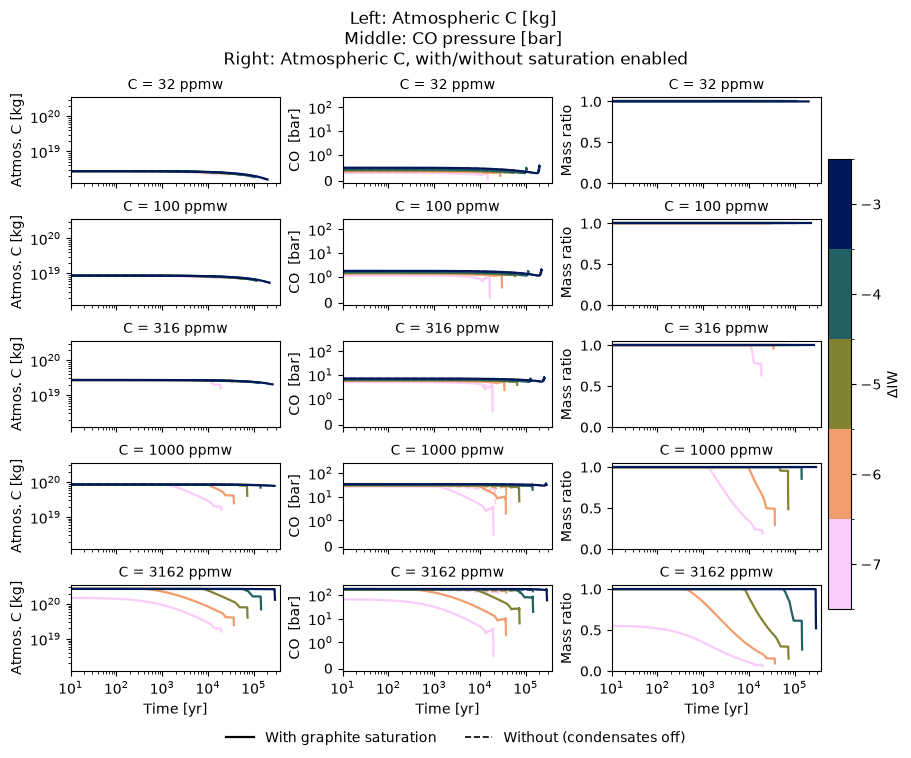

,dIW,C,C_atm_with,C_atm_without,C_graphite,t_end_with,t_end_without,ratio
0,-7.0,31.622777,2.216407e+18,2.216407e+18,5.378642e-06,14911.519274,14911.505869,1.000000
1,-7.0,100.000000,7.331307e+18,7.331307e+18,3.087483e-05,16522.855301,16522.855301,1.000000
2,-7.0,316.227766,1.599660e+19,2.536157e+19,9.379620e+18,18888.793153,19073.813392,0.630742
3,-7.0,1000.000000,1.619547e+19,8.458514e+19,6.803594e+19,19782.702546,21726.466954,0.191469
4,-7.0,3162.277660,1.626800e+19,2.705239e+20,2.533562e+20,19758.862612,25503.432610,0.060135
5,-6.0,31.622777,2.239230e+18,2.239194e+18,3.781892e-06,27921.657087,27929.284310,1.000016
6,-6.0,100.000000,7.307716e+18,7.307817e+18,2.135079e-05,30380.788836,30371.512563,0.999986
7,-6.0,316.227766,2.408615e+19,2.499923e+19,9.130853e+17,34323.300152,34323.300152,0.963475
8,-6.0,1000.000000,2.484648e+19,8.404846e+19,5.903533e+19,37060.691910,37794.225163,0.295621
9,-6.0,3162.277660,2.493872e+19,2.701958e+20,2.444485e+20,37123.324810,38631.185938,0.092299


In [48]:
cases = lg.get_cases(pgrid_dir, only_completed=True)
cfgs = lg.load_configs(cases)
helps, _ = lg.load_helpfiles(cases)

dIW = np.array(lg.access_configs(cfgs, "outgas.fO2_shift_IW"), dtype=float)
Cb = np.array(lg.access_configs(cfgs, "planet.elements.C_budget"), dtype=float)
cond = np.array(lg.access_configs(cfgs, "outgas.atmodeller.include_condensates"), dtype=bool)
C_mode = lg.access_configs(cfgs, "planet.elements.C_mode")[0]

species = "CO"

# Pair the runs with and without condensates at each grid point
runs = {}
for hf, x, y, on in zip(helps, dIW, Cb, cond):
    runs.setdefault((x, y), {})[on] = (np.array(hf["Time"], dtype=float),
                                       np.array(hf["C_kg_atm"], dtype=float),
                                       np.array(hf["C_kg_condensed"], dtype=float),
                                       np.array(hf[f"{species}_bar"], dtype=float))
pairs = {k: v for k, v in runs.items() if len(v) == 2}
print(f"{len(pairs)} of {len(runs)} grid points have both runs completed")

def ratio_with_without(t_on, c_on, t_off, c_off):
    """Atmospheric C with condensates over that without, at the times of the run with them.

    The run without is interpolated in log-log onto those times, within the time range
    both runs cover.
    """
    keep = np.r_[np.diff(t_off) > 0, True] & (t_off > 0)
    t_off, c_off = t_off[keep], c_off[keep]
    ok = (t_on >= t_off[0]) & (t_on <= t_off[-1])
    c_interp = 10 ** np.interp(np.log10(t_on[ok]), np.log10(t_off), np.log10(c_off))
    return t_on[ok], c_on[ok] / c_interp

dIW_v = np.unique([k[0] for k in pairs])
C_v = np.unique([k[1] for k in pairs])
cmap_f = cmc.batlow_r
norm_f = BoundaryNorm(np.concatenate([dIW_v - 0.5, [dIW_v[-1] + 0.5]]), cmap_f.N)

nrow = len(C_v)
fig, axs = plt.subplots(nrow, 3, figsize=(9.0, 1.5 * nrow), sharex=True, sharey="col",
                        squeeze=False, layout="constrained")
for (ax_l, ax_m, ax_r), c in zip(axs, C_v):
    for x in dIW_v:
        if (x, c) not in pairs:
            continue
        col = cmap_f(norm_f(x))
        (t1, a1, _, p1)  = pairs[(x, c)][True] # allows saturated run
        (t0, a0, _, p0)  = pairs[(x, c)][False] # disallows saturated run

        ax_l.plot(t1[t1 > 0], a1[t1 > 0], color=col, lw=1.6)
        ax_l.plot(t0[t0 > 0], a0[t0 > 0], color=col, lw=1.2, ls="--")

        ax_m.plot(t1[t1 > 0], p1[t1 > 0], color=col, lw=1.6)
        ax_m.plot(t0[t0 > 0], p0[t0 > 0], color=col, lw=1.2, ls="--")

        ax_r.plot(*ratio_with_without(t1, a1, t0, a0), color=col, lw=1.6)
    ax_l.set_yscale("log")
    ax_m.set_yscale("symlog", linthresh=1)
    ax_r.set_ylim(0,1.05)
    for ax in (ax_l, ax_m, ax_r):
        ax.set_xscale("log")
        ax.set_xlim(left=10)
        ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)

for i in range(nrow):
    axs[i, 0].set_ylabel("Atmos. C [kg]")
    axs[i, 1].set_ylabel(f"{species}  [bar]")
    axs[i, 2].set_ylabel("Mass ratio")

fig.suptitle("Left: Atmospheric C [kg] \n"
             f"Middle: {species} pressure [bar] \n"
             "Right: Atmospheric C, with/without saturation enabled")

for ax in axs[-1]:
    ax.set_xlabel("Time [yr]")
    
sm = plt.cm.ScalarMappable(cmap=cmap_f, norm=norm_f)
cb = fig.colorbar(sm, ax=axs, ticks=dIW_v, pad=0.01, fraction=0.03)
cb.set_label(r"$\Delta$IW")
styles = [Line2D([], [], color="k", lw=1.6), Line2D([], [], color="k", lw=1.2, ls="--")]
fig.legend(styles, ["With graphite saturation", "Without (condensates off)"],
           loc="outside lower center", ncol=2, frameon=False)
fig.savefig(os.path.join(outdir, "atm_carbon_with_without_graphite.pdf"), bbox_inches="tight")
plt.show()

# Endpoint of each run: atmospheric C with and without graphite, and the graphite held
end = pd.DataFrame([dict(dIW=x, C=c,
                         C_atm_with=v[True][1][-1], C_atm_without=v[False][1][-1],
                         C_graphite=v[True][2][-1],
                         t_end_with=v[True][0][-1], t_end_without=v[False][0][-1])
                    for (x, c), v in sorted(pairs.items())])
end["ratio"] = end["C_atm_with"] / end["C_atm_without"]
end.to_csv(os.path.join(outdir, "atm_carbon_with_without_graphite.csv"), index=False)
end